# YouTube viral classification

[Source](https://www.kaggle.com/datasets/vedauv/what-makes-a-yt-video-go-viral-12000-vids): 12,000 synthetic videos, version 1, CC0. This is current-snapshot classification; engagement counts are generated from views.

## 1. Setup and loading

Run all cells from the project root with the `.venv` kernel. Dependencies: `requirements-youtube-viral.txt`. The source archive downloads only if absent.

In [1]:
# OpenAI Codex assisted with the notebook text and code on 22 October 2026.
from pathlib import Path
from urllib.request import urlopen
import hashlib
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, ConfusionMatrixDisplay,
    f1_score, log_loss, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

In [2]:
SEED = 2026
TEST_SIZE = 1 / 3
N_FOLDS = 5
C_VALUES = np.logspace(-3, 3, 7)
DECISION_THRESHOLD = 0.5

ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "youtube_viral" / "raw"
ARCHIVE = RAW_DIR / "youtube-viral-v1.zip"
CSV_MEMBER = "viral_videos.csv"
DOWNLOAD_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "vedauv/what-makes-a-yt-video-go-viral-12000-vids?datasetVersionNumber=1"
)
EXPECTED_SHA256 = "8f7c464ec382ab9d3ae50ede517548bd1940530dfe26f74ea64e2f2cbdf60b1d"
OUTPUT_DIR = ROOT / "outputs" / "youtube_viral_baseline"

In [3]:
RAW_DIR.mkdir(parents=True, exist_ok=True)
if not ARCHIVE.exists():
    with urlopen(DOWNLOAD_URL, timeout=90) as response:
        archive_bytes = response.read()
    assert hashlib.sha256(archive_bytes).hexdigest() == EXPECTED_SHA256, "Unexpected source archive."
    ARCHIVE.write_bytes(archive_bytes)

source_sha256 = hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()
assert source_sha256 == EXPECTED_SHA256, "Source archive changed; review before continuing."
with zipfile.ZipFile(ARCHIVE) as archive:
    source = pd.read_csv(archive.open(CSV_MEMBER))

source.index.name = "source_record_index"
print(f"Source version 1: {source.shape[0]:,} rows, {source.shape[1]} columns")
display(source.head())

Source version 1: 12,000 rows, 15 columns


,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
source_record_index,,,,,,,,,,,,,,,
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1


## 2. Data checks

In [4]:
quality = pd.DataFrame({
    "missing_n": source.isna().sum(),
    "unique_n": source.nunique(dropna=True),
})
quality["missing_pct"] = 100 * quality["missing_n"] / len(source)
display(quality)
audit_counts = pd.Series({
    "rows": len(source),
    "exact_duplicate_extra_rows": int(source.duplicated().sum()),
    "duplicate_video_ids": int(source["video_id"].duplicated().sum()),
    "duplicate_records_without_id": int(source.drop(columns="video_id").duplicated().sum()),
}, name="count")
display(audit_counts.to_frame())
assert source.shape == (12_000, 15)
assert not source.isna().any().any(), "Review missing values before fitting."
assert source["video_id"].is_unique
assert not source.drop(columns="video_id").duplicated().any()

,missing_n,unique_n,missing_pct
video_id,0,12000,0.0
category,0,15,0.0
duration_sec,0,1350,0.0
title_length,0,99,0.0
thumbnail_face,0,2,0.0
upload_hour,0,24,0.0
upload_day,0,7,0.0
tags_count,0,44,0.0
description_length,0,1256,0.0
subscriber_count,0,11948,0.0


,count
rows,12000
exact_duplicate_extra_rows,0
duplicate_video_ids,0
duplicate_records_without_id,0


In [5]:
COUNT_COLUMNS = [
    "duration_sec", "title_length", "tags_count", "description_length",
    "subscriber_count", "views", "likes", "comments", "shares",
]
counts = source[COUNT_COLUMNS]
assert np.isfinite(counts.to_numpy()).all()
assert counts.ge(0).all().all()
assert counts.eq(np.floor(counts)).all().all()
assert source["duration_sec"].gt(0).all()
assert source["upload_hour"].between(0, 23).all()
assert source["upload_hour"].eq(np.floor(source["upload_hour"])).all()
assert source["upload_day"].isin(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).all()
assert source["thumbnail_face"].isin([0, 1]).all()
assert source["viral"].isin([0, 1]).all()
assert source["category"].nunique() == 15
print("All deterministic validity checks passed; all source rows are retained.")

All deterministic validity checks passed; all source rows are retained.


### Target check

Use the supplied `viral` labels (top 20% by views), kept fixed across splits.

In [6]:
source_view_cutoff = source["views"].quantile(0.8)
definition_labels = source["views"].ge(source_view_cutoff).astype("int64")
assert definition_labels.equals(source["viral"])
target_counts = source["viral"].value_counts().sort_index().rename("n").to_frame()
target_counts["fraction"] = target_counts["n"] / len(source)
display(target_counts)
print(f"Source-label audit only: 80th percentile of views = {source_view_cutoff:,.0f}")
print("Keep the original viral labels fixed; do not recompute quantiles by split or fold.")

,n,fraction
viral,,
0,9600,0.8
1,2400,0.2


Source-label audit only: 80th percentile of views = 734,315
Keep the original viral labels fixed; do not recompute quantiles by split or fold.


## 3. Inputs and split

12 predictors, excluding `views` and `video_id`. Stratified split: 8,000 training / 4,000 test rows; seed 2026.

In [7]:
SCALED_INPUTS = ["duration_sec", "title_length", "thumbnail_face", "tags_count", "description_length"]
LOG_INPUTS = ["subscriber_count", "likes", "comments", "shares"]
CATEGORICAL_INPUTS = ["category", "upload_hour", "upload_day"]
FEATURE_COLUMNS = SCALED_INPUTS + LOG_INPUTS + CATEGORICAL_INPUTS
EXCLUDED_COLUMNS = {"video_id", "views", "viral"}

X = source[FEATURE_COLUMNS].copy()
y = source["viral"].astype("int64").copy()
assert set(FEATURE_COLUMNS) == set(source.columns) - EXCLUDED_COLUMNS
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS)) == 12
assert set(X.columns).isdisjoint(EXCLUDED_COLUMNS)
assert X.index.equals(y.index) and X.index.is_unique
assert not X.duplicated().any(), "Review repeated-input groups before splitting."
print(f"Analytical data: n={len(X):,}, input d={X.shape[1]}, target=viral")
display(X.head())

Analytical data: n=12,000, input d=12, target=viral


,duration_sec,title_length,thumbnail_face,tags_count,description_length,subscriber_count,likes,comments,shares,category,upload_hour,upload_day
source_record_index,,,,,,,,,,,,
0,517,64,1,27,429,907474,20610,4029,7208,Beauty,23,Wed
1,495,47,1,10,222,1004641,3907,554,554,Tech,23,Mon
2,311,76,0,13,520,168170,1021,77,122,Beauty,17,Mon
3,590,69,0,17,309,285593,2587,142,964,Fitness,0,Mon
4,380,58,1,0,101,1073326,22993,1825,2611,Tech,19,Mon


In [8]:
train_ids, test_ids = train_test_split(
    X.index.to_numpy(), test_size=TEST_SIZE, random_state=SEED, stratify=y,
)
train_ids, test_ids = np.sort(train_ids), np.sort(test_ids)
X_train, X_test = X.loc[train_ids].copy(), X.loc[test_ids].copy()
y_train, y_test = y.loc[train_ids].copy(), y.loc[test_ids].copy()

assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(X.index)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)
display(pd.DataFrame({
    "n": [len(X_train), len(X_test)],
    "fraction": [len(X_train) / len(X), len(X_test) / len(X)],
}, index=["training/development", "final test"]))

split_indices = source[["video_id"]].copy()
split_indices["split"] = "training"
split_indices.loc[test_ids, "split"] = "test"

,n,fraction
training/development,8000,0.666667
final test,4000,0.333333


## 4. Training EDA

In [9]:
display(X_train[SCALED_INPUTS + LOG_INPUTS].describe().T)
training_class_counts = y_train.value_counts().sort_index().rename("n").to_frame()
training_class_counts["fraction"] = training_class_counts["n"] / len(y_train)
display(training_class_counts)
display(X_train.isna().sum().rename("missing_n_training").to_frame())

,count,mean,std,min,25%,50%,75%,max
duration_sec,8000.0,6.310562e+02,2.850181e+02,30.0,407.00,613.0,823.25,1829.0
title_length,8000.0,5.448125e+01,1.481995e+01,10.0,45.00,55.0,65.00,109.0
thumbnail_face,8000.0,4.022500e-01,4.903825e-01,0.0,0.00,0.0,1.00,1.0
tags_count,8000.0,1.458013e+01,7.787324e+00,0.0,9.00,14.0,20.00,43.0
description_length,8000.0,5.070901e+02,2.864582e+02,0.0,298.00,504.0,707.00,1528.0
subscriber_count,8000.0,1.004866e+06,2.484538e+06,3636.0,157696.25,383545.0,944635.00,85804273.0
likes,8000.0,3.746155e+04,1.626656e+05,6.0,2762.50,8686.0,26731.50,6434658.0
comments,8000.0,4.805252e+03,2.331287e+04,0.0,315.75,1013.0,3190.25,1017685.0
shares,8000.0,9.564177e+03,4.533769e+04,1.0,632.00,2052.5,6478.75,1723680.0


,n,fraction
viral,,
0,6400,0.8
1,1600,0.2


,missing_n_training
duration_sec,0
title_length,0
thumbnail_face,0
tags_count,0
description_length,0
subscriber_count,0
likes,0
comments,0
shares,0
category,0


In [10]:
category_summary = (
    X_train[["category"]].join(y_train)
    .groupby("category")["viral"].agg(n="size", viral_rate="mean")
    .sort_index()
)
display(category_summary)
display(X_train["upload_day"].value_counts().rename("n_training").to_frame())

,n,viral_rate
category,,
Beauty,528,0.250000
Comedy,531,0.327684
Cooking,506,0.181818
DIY,511,0.133072
Education,503,0.123260
Finance,544,0.165441
Fitness,523,0.116635
Gaming,550,0.232727
Music,531,0.559322


,n_training
upload_day,
Sun,1170
Mon,1160
Fri,1160
Wed,1147
Thu,1147
Sat,1111
Tue,1105


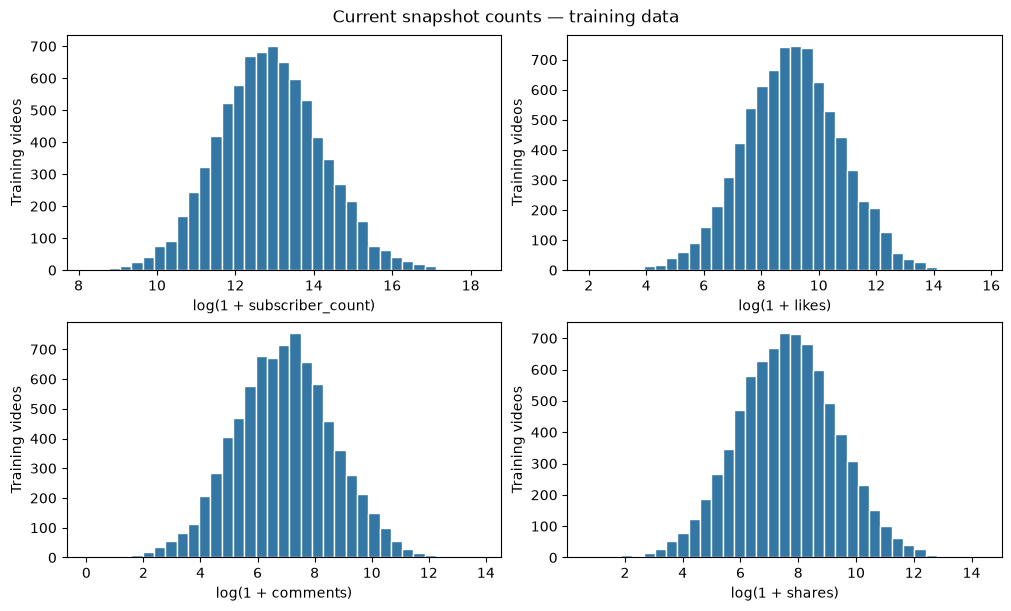

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for axis, column in zip(axes.flat, LOG_INPUTS):
    axis.hist(np.log1p(X_train[column]), bins=35, color="#3477A5", edgecolor="white")
    axis.set(xlabel=f"log(1 + {column})", ylabel="Training videos")
fig.suptitle("Current snapshot counts — training data")
plt.show()

## 5. Logistic regression

Preprocessing stays inside CV folds. Select `C` by five-fold validation log loss.

In [12]:
preprocess = ColumnTransformer([
    ("scaled", StandardScaler(), SCALED_INPUTS),
    ("log_scaled", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]), LOG_INPUTS),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_INPUTS),
], remainder="drop")

logistic_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("logistic", LogisticRegression(solver="lbfgs", max_iter=3000, random_state=SEED)),
])
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
print("Training folds:", len(cv_splits), "| C grid:", C_VALUES)

Training folds: 5 | C grid: [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03]


In [13]:
search = GridSearchCV(
    logistic_pipeline, {"logistic__C": C_VALUES},
    scoring="neg_log_loss", cv=cv_splits, refit=True, n_jobs=1,
    return_train_score=False, error_score="raise",
)
search.fit(X_train, y_train)
selected_model = search.best_estimator_
cv_results = pd.DataFrame({
    "C": [float(c) for c in search.cv_results_["param_logistic__C"]],
    "mean_validation_log_loss": -search.cv_results_["mean_test_score"],
    "fold_sd_log_loss": search.cv_results_["std_test_score"],
    "rank": search.cv_results_["rank_test_score"],
})
display(cv_results.sort_values("C").reset_index(drop=True))
print("Selected C:", search.best_params_["logistic__C"])
print("Selected mean validation log loss:", -search.best_score_)
if search.best_params_["logistic__C"] in (C_VALUES[0], C_VALUES[-1]):
    print("Selected C is at a grid boundary; this run retains the predeclared grid.")
assert selected_model.n_features_in_ == 12
assert list(selected_model.feature_names_in_) == FEATURE_COLUMNS
assert selected_model.named_steps["logistic"].n_iter_.max() < 3000
encoded_names = selected_model.named_steps["preprocess"].get_feature_names_out()
print("Transformed input dimension:", len(encoded_names))

,C,mean_validation_log_loss,fold_sd_log_loss,rank
0,0.001,0.225728,0.001617,7
1,0.010,0.140434,0.003739,6
2,0.100,0.116640,0.006114,5
3,1.000,0.112549,0.006733,1
4,10.000,0.113041,0.007124,2
5,100.000,0.113221,0.007231,3
6,1000.000,0.113241,0.007241,4


Selected C: 1.0
Selected mean validation log loss: 0.11254934105036349
Transformed input dimension: 55


### Class-prior reference

In [14]:
dummy_cv_loss = -cross_val_score(
    DummyClassifier(strategy="prior"), X_train, y_train,
    scoring="neg_log_loss", cv=cv_splits, n_jobs=1, error_score="raise",
)
dummy_model = DummyClassifier(strategy="prior").fit(X_train, y_train)
cv_comparison = pd.DataFrame([
    {"model": "L2 logistic (selected C)", "mean_validation_log_loss": -search.best_score_,
     "fold_sd_log_loss": search.cv_results_["std_test_score"][search.best_index_]},
    {"model": "Training class prior", "mean_validation_log_loss": dummy_cv_loss.mean(),
     "fold_sd_log_loss": dummy_cv_loss.std(ddof=0)},
])
display(cv_comparison)

,model,mean_validation_log_loss,fold_sd_log_loss
0,L2 logistic (selected C),0.112549,0.006733
1,Training class prior,0.500402,0.000000


## 6. Test evaluation

Classification threshold: 0.5. No further tuning on test results.

In [15]:
fitted_models = {"L2 logistic": selected_model, "Training class prior": dummy_model}
test_probabilities = {}
result_rows = []
for model_name, fitted_model in fitted_models.items():
    positive_column = np.flatnonzero(fitted_model.classes_ == 1).item()
    probabilities = fitted_model.predict_proba(X_test)[:, positive_column]
    assert probabilities.shape == (len(y_test),)
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    predictions = (probabilities >= DECISION_THRESHOLD).astype("int64")
    test_probabilities[model_name] = probabilities
    result_rows.append({
        "model": model_name,
        "log_loss": log_loss(y_test, probabilities, labels=[0, 1]),
        "average_precision": average_precision_score(y_test, probabilities),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
    })
test_results = pd.DataFrame(result_rows).set_index("model")
display(test_results)

,log_loss,average_precision,roc_auc,accuracy,precision,recall,f1
model,,,,,,,
L2 logistic,0.115813,0.955589,0.986633,0.94825,0.891678,0.84375,0.867052
Training class prior,0.500402,0.200000,0.500000,0.80000,0.000000,0.00000,0.000000


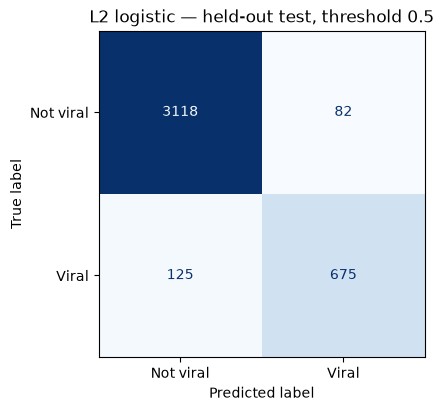

In [16]:
logistic_predictions = (test_probabilities["L2 logistic"] >= DECISION_THRESHOLD).astype("int64")
fig, axis = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_predictions, labels=[0, 1], display_labels=["Not viral", "Viral"],
    cmap="Blues", colorbar=False, ax=axis,
)
axis.set_title("L2 logistic — held-out test, threshold 0.5")
plt.show()

## 7. Exports

Splits, scores and predictions: `outputs/youtube_viral_baseline/`.

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
test_predictions = source.loc[test_ids, ["video_id", "viral"]].copy()
test_predictions["logistic_probability"] = test_probabilities["L2 logistic"]
test_predictions["prior_probability"] = test_probabilities["Training class prior"]
test_predictions["logistic_prediction"] = logistic_predictions

split_indices.to_csv(OUTPUT_DIR / "split_indices.csv")
cv_results.to_csv(OUTPUT_DIR / "cv_results.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_results.csv")
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv")